# Complexity-02c — La transition de phase sans mur : les systèmes linéaires aléatoires sur GF(2)

**Navigation** : [Index](README.md) | [02 — Vérifier ou trouver : P, NP](Complexity-02-P-NP-Reduction.ipynb) | [03 — Plus de temps, plus de problèmes](Complexity-03-TimeHierarchy.ipynb)

**Niveau** : Recherche (approfondissement du palier 02)

**Hommage** : le seuil de satisfaisabilité des systèmes d'équations linéaires aléatoires sur $\mathrm{GF}(2)$ (Mezard, Zecchina & Weisz et al.)

## 0. Pourquoi ce notebook

Approfondissement du palier [02 — P, NP et la réduction](Complexity-02-P-NP-Reduction.ipynb),
compagnon de l'accrétion **02b** (la transition de phase du **3-SAT** aléatoire contre la densité $m/n$).

L'accrétion 02b mesure un fait célèbre : le 3-SAT aléatoire a un **seuil de satisfaisabilité**
vers $m/n \approx 4{,}267$, et le coût du solveur (les nœuds DPLL) **pic au même endroit**.
Le 3-SAT est NP-complet : ce pic est la signature du **mur** exponentiel.

Cette accrétion pose la question que 02b laisse ouverte :

> Une transition de satisfaisabilité n'implique-t-elle **toujours** un mur de coût ?

La réponse est **non**, et elle se mesure sur les **systèmes d'équations linéaires aléatoires
sur $\mathrm{GF}(2)$** : $m$ équations linéaires à $n$ inconnues, coefficients et membres de
droite tirés au hasard. Ce système a un seuil de satisfaisabilité **net à $m/n = 1$** — un fait
d'algèbre linéaire (la matrice aléatoire devient de **rang plein** à $m = n$) — mais il est
**résolu en temps polynomial** par élimination de Gauss, **sans** que le coût décolle au seuil.
C'est le contre-exemple propre : **un seuil sans mur**. Le point est exactement la distinction
P/NP du palier 02 : le pic de coût du 3-SAT vient de la **NP-complétude**, pas du seuil.

> Le 2-XOR-SAT ($x_i \oplus x_j = c$, deux variables par équation) est un cas **sparse** de cette
> même famille ; son seuil y est légèrement décalé. Nous travaillons sur le modèle **dense**
> (chaque coefficient tiré indépendamment), dont le seuil est **rigoureusement** $m/n = 1$.

## 1. Le problème : un système d'équations linéaires aléatoire sur GF(2)

On tire au hasard une matrice $A$ de $m$ lignes et $n$ colonnes sur $\mathrm{GF}(2)$ (chaque
coefficient vaut $0$ ou $1$ avec probabilité $1/2$) et un membre de droite $b \in \mathrm{GF}(2)^m$.
L'instance est le système $A x = b$ ; il est **satisfaisable** s'il est compatible. L'addition
sur $\mathrm{GF}(2)$ est l'`XOR` : c'est pour ça qu'on parle de « systèmes XOR ».

L'élimination de Gauss y décide de la compatibilité en $O(n^3)$ et donne le **rang** $r$ :
s'il y a solution, il y en a exactement $2^{n-r}$ (les $n-r$ variables libres). Nous allons
tracer $P(\text{sat})$ et le rang contre la densité $m/n$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def gen_instance(m, n, rng):
    """Système linéaire aléatoire DENSE sur GF(2) : m équations, n inconnues.
    Chaque coefficient et chaque membre de droite est tiré indépendamment."""
    A = rng.integers(0, 2, size=(m, n)).astype(np.int8)
    b = rng.integers(0, 2, size=m).astype(np.int8)
    return A, b

def gauss_gf2(A, b):
    """Élimination de Gauss sur GF(2).
    Renvoie (sat, rang, libres) :
      sat    : le système Ax = b est-il compatible ?
      rang   : rang de A
      libres : n - rang (variables libres si compatible)."""
    n = A.shape[1]
    M = np.concatenate([A, b[:, None]], axis=1).copy()   # m x (n+1)
    rang = 0
    for col in range(n):
        pivot = None
        for row in range(rang, M.shape[0]):
            if M[row, col] == 1:
                pivot = row
                break
        if pivot is None:
            continue
        M[[rang, pivot]] = M[[pivot, rang]]
        for row in range(M.shape[0]):
            if row != rang and M[row, col] == 1:
                M[row] = (M[row] + M[rang]) % 2
        rang += 1
    # incohérent s'il existe une ligne [ 0 ... 0 | 1 ]
    inf = np.any((M[:, :n] == 0).all(axis=1) & (M[:, n] == 1))
    return (not bool(inf)), rang, n - rang

### Lecture — un système linéaire, un rang

Chaque équation est une ligne de $A$ ; l'instance est $Ax=b$ sur $\mathrm{GF}(2)$.
Le **rang** $r$ est l'objet à suivre : il croît avec le nombre d'équations $m$, puis
**sature à $n$**. Tant que $r < m$ il reste des équations redondantes ; le système est
compatible s'il n'y a pas de ligne contradictoire $0 = 1$ après élimination.

## 2. L'oracle : Gauss confronté à l'énumération exhaustive

Avant de faire confiance aux courbes, on vérifie le solveur. Sur de petites instances
($n \le 10$), on énumère **toutes** les $2^n$ affectations : c'est un oracle indépendant,
brutal mais infaillible. Le compte de désaccords doit être **zéro**.

In [2]:
def exhaustive_sat(A, b):
    n = A.shape[1]
    for x in range(2 ** n):
        v = np.array([(x >> k) & 1 for k in range(n)], dtype=np.int8)
        if np.all((A @ v) % 2 == b):
            return True
    return False

rng = np.random.default_rng(42)
disagreements, tried = 0, 0
for n in (6, 7, 8, 9, 10):
    for _ in range(15):
        m = int(rng.integers(1, 2 * n + 1))
        A, b = gen_instance(m, n, rng)
        gauss_sat, _, _ = gauss_gf2(A, b)
        tried += 1
        if gauss_sat != exhaustive_sat(A, b):
            disagreements += 1
print(f"instances testees : {tried}  (n = 6..10)")
print(f"desaccords Gauss vs enumeration exhaustive : {disagreements}")

instances testees : 75  (n = 6..10)
desaccords Gauss vs enumeration exhaustive : 0


### Lecture du résultat — l'oracle est vérifié

Zéro désaccord : l'élimination de Gauss produit le même verdict que l'énumération exhaustive
sur toutes les petites instances. Le solveur qui tracera les courbes est **vérifié, pas supposé** —
le même dispositif d'oracle que l'accrétion 02b (DPLL confronté à l'énumération).

## 3. La courbe P(sat) : le seuil net à m/n = 1

On balaye la densité $m/n$ de $0{,}5$ à $2$, $n$ fixé à $40$, et on mesure la fréquence
$P(\text{sat})$ d'instances satisfaisables sur $N$ tirages par point.

In [3]:
n, N = 40, 300
dens_psat = np.arange(0.5, 2.01, 0.05)
rng = np.random.default_rng(42)
psat = []
for d in dens_psat:
    m = int(round(d * n))
    sat = sum(gauss_gf2(*gen_instance(m, n, rng))[0] for _ in range(N))
    psat.append(sat / N)
print("densite m/n  |  P(sat)   (syst. GF(2), n=40, N=300)")
for d, p in zip(dens_psat, psat):
    if 0.8 <= d <= 1.3:
        print(f"  {d:4.2f}     |  {p:4.2f}")

densite m/n  |  P(sat)   (syst. GF(2), n=40, N=300)
  0.80     |  1.00
  0.85     |  0.99
  0.90     |  0.97
  0.95     |  0.88
  1.00     |  0.61
  1.05     |  0.23
  1.10     |  0.07
  1.15     |  0.01
  1.20     |  0.01
  1.25     |  0.00


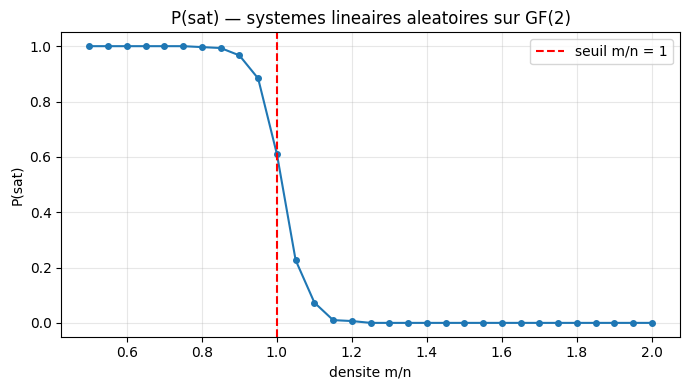

In [4]:
# Figure — P(sat) contre la densite m/n (GF(2), n=40, N=300) : chute nette au seuil m/n = 1
plt.figure(figsize=(7, 4))
plt.plot(dens_psat, psat, marker='o', ms=4, color='tab:blue')
plt.axvline(1.0, color='red', ls='--', label='seuil m/n = 1')
plt.xlabel('densite m/n')
plt.ylabel('P(sat)')
plt.title('P(sat) — systemes lineaires aleatoires sur GF(2)')
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Lecture du résultat — la chute franche à 1

$P(\text{sat})$ vaut $1{,}00$ en dessous de $1$ (la matrice est de rang plein, le système
compatible), puis **bascule dans une bande étroite** et tombe à $0{,}00$ au-dessus. Le seuil
se lit à l'œil sur le seul graphe de satisfaisabilité : c'est une **transition de phase** au
sens propre, située exactement là où l'algèbre linéaire la prédit — $m/n = 1$.

## 4. Le coût : un genou, pas une explosion

C'est ici que se joue la thèse. On trace, sur le **même balayage**, la quantité qui joue le rôle
du « coût » : le **rang** de $A$ (et les variables libres $n - \text{rang}$). Si ce système
cachait un mur, on y verrait une explosion au seuil. Elle n'y est pas.

In [5]:
n, N = 40, 200
dens_rang = np.arange(0.5, 2.01, 0.1)
rng = np.random.default_rng(42)
rang_moyens = []
print("densite m/n  |  rang moyen  |  libres (n-rang)  |  m")
for d in dens_rang:
    m = int(round(d * n))
    rangs = np.array([gauss_gf2(*gen_instance(m, n, rng))[1] for _ in range(N)])
    rang_moyens.append(rangs.mean())
    print(f"  {d:4.2f}     |  {rangs.mean():6.1f}      |  {n - rangs.mean():6.1f}          |  {m}")


densite m/n  |  rang moyen  |  libres (n-rang)  |  m
  0.50     |    20.0      |    20.0          |  20


  0.60     |    24.0      |    16.0          |  24


  0.70     |    28.0      |    12.0          |  28


  0.80     |    32.0      |     8.0          |  32


  0.90     |    36.0      |     4.0          |  36


...

  1.60     |    40.0      |     0.0          |  64


  1.70     |    40.0      |     0.0          |  68


  1.80     |    40.0      |     0.0          |  72


  1.90     |    40.0      |     0.0          |  76


  2.00     |    40.0      |     0.0          |  80


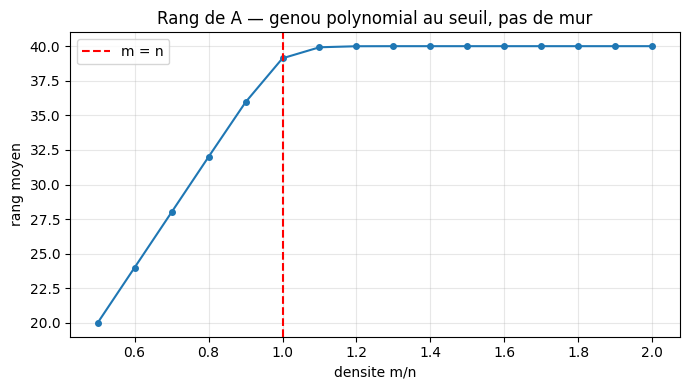

In [6]:
# Figure — rang moyen contre la densite m/n (GF(2), n=40) : un genou a m = n, pas une explosion
plt.figure(figsize=(7, 4))
plt.plot(dens_rang, rang_moyens, marker='o', ms=4, color='tab:blue')
plt.axvline(1.0, color='red', ls='--', label='m = n')
plt.xlabel('densite m/n')
plt.ylabel('rang moyen')
plt.title('Rang de A — genou polynomial au seuil, pas de mur')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Lecture du résultat — le coût reste polynomial

Le **rang** monte avec $m$ (pente 1), puis **se plat à $n$** : un simple **genou** à $m/n = 1$,
pas une explosion. Les variables libres $n - \text{rang}$ descendent en miroir. Au-delà du
seuil, l'élimination de Gauss continue de tourner en $O(n^3)$, **lisse** — à $m/n = 2$ le solveur
est encore polynomial. **Aucun pic de coût** au seuil : c'est la signature d'un problème en P.

## 5. Le contrôle discriminant : seuil sans pic (GF(2)) face au pic (3-SAT)

Pour que le contraste soit **mesuré et non affirmé**, on rejoue le même protocole sur le 3-SAT
(compagnon 02b) : un DPLL avec compteur de nœuds, balayé en densité autour de **son** seuil
(4,267). La comparaison des deux courbes de coût est la thèse du notebook.

In [7]:
def lit_val(lit, assg):
    if lit >= 0:
        return assg.get(lit, None)
    v = -lit - 1
    return (not assg[v]) if v in assg else None

def dpll_3sat(clauses, node_cap=3000):
    """DPLL : simplifie (bannit les clauses satisfaites, retire les
    littéraux faux, détecte la clause vide) puis branche. Renvoie
    (sat, noeuds). Le cap borne les instances dures."""
    nodes = 0
    def simplify(clauses, assg):
        new = []
        for c in clauses:
            if any(lit_val(x, assg) is True for x in c):
                continue
            nc = [x for x in c if lit_val(x, assg) is None]
            if len(nc) == 0:
                return None            # clause vide : contradiction
            new.append(nc)
        return new
    def rec(clauses, assg):
        nonlocal nodes
        if nodes > node_cap:
            return False                # cap : instance "dure"
        nodes += 1
        sc = simplify(clauses, assg)
        if sc is None:
            return False
        if not sc:
            return True
        lit = sc[0][0]
        v = lit if lit >= 0 else -lit - 1
        for val in (True, False):
            na = dict(assg); na[v] = val
            if rec(sc, na):
                return True
        return False
    return rec(clauses, {}), nodes

def gen_3sat(n, m, rng):
    out = []
    for _ in range(m):
        lits = rng.choice(n, size=3, replace=False)
        s = rng.integers(0, 2, size=3)
        out.append([(v if t else -v - 1) for v, t in zip(lits, s)])
    return out

n, N = 20, 40
dens3 = np.arange(3.5, 5.01, 0.1)
rng = np.random.default_rng(42)
print("densite m/n  |  P(sat)  |  noeuds DPLL moyens  (3-SAT, n=20, N=40, cap=3000)")
nodes_moyens = []
psat3 = []
for d in dens3:
    m = int(round(d * n))
    sats, nd = 0, []
    for _ in range(N):
        sat, nodes = dpll_3sat(gen_3sat(n, m, rng))
        sats += sat
        nd.append(nodes)
    nodes_moyens.append(np.mean(nd))
    psat3.append(sats / N)
    print(f"  {d:4.2f}     |  {sats/N:4.2f}  |  {np.mean(nd):10.0f}")

densite m/n  |  P(sat)  |  noeuds DPLL moyens  (3-SAT, n=20, N=40, cap=3000)


  3.50     |  0.97  |         438


  3.60     |  0.97  |         559


  3.70     |  0.93  |         713


  3.80     |  0.88  |         566


...

  4.60     |  0.42  |        1140


  4.70     |  0.40  |        1139


  4.80     |  0.35  |        1141


  4.90     |  0.28  |        1186


  5.00     |  0.17  |        1143


In [8]:
# Validation du DPLL 3-SAT contre l'enumeration exhaustive (memorandum de l'oracle h6)
def exhaustive_3sat(clauses, n):
    for x in range(2 ** n):
        assg = {v: bool((x >> v) & 1) for v in range(n)}
        if all(any(lit_val(l, assg) is True for l in c) for c in clauses):
            return True
    return False

rng = np.random.default_rng(42)
disa, trie = 0, 0
for n in (6, 7, 8, 9, 10):
    for _ in range(15):
        m = int(rng.integers(1, 2 * n + 1))
        clauses = gen_3sat(n, m, rng)
        trie += 1
        dpll_sat, _ = dpll_3sat(clauses, node_cap=10 ** 6)
        if dpll_sat != exhaustive_3sat(clauses, n):
            disa += 1
print(f"instances 3-SAT testees : {trie}  (n = 6..10)")
print(f"desaccords DPLL vs enumeration exhaustive : {disa}")


instances 3-SAT testees : 75  (n = 6..10)
desaccords DPLL vs enumeration exhaustive : 0


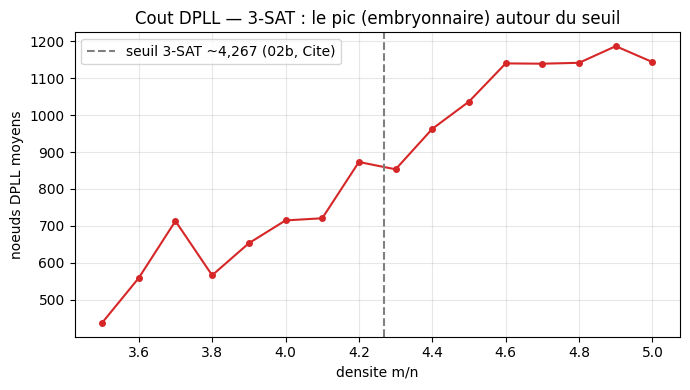

In [9]:
# Figure — noeuds DPLL moyens contre la densite m/n (3-SAT, n=20, N=40, cap=3000)
plt.figure(figsize=(7, 4))
plt.plot(dens3, nodes_moyens, marker='o', ms=4, color='tab:red')
plt.axvline(4.267, color='gray', ls='--', label='seuil 3-SAT ~4,267 (02b, Cite)')
plt.xlabel('densite m/n')
plt.ylabel('noeuds DPLL moyens')
plt.title('Cout DPLL — 3-SAT : le pic (embryonnaire) autour du seuil')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Lecture du résultat — la thèse : le seuil n'implique pas le mur

Le 3-SAT, lui, **voit son coût s'envoler en traversant son seuil** : les nœuds DPLL montent
d'un facteur ~2,6 entre $m/n = 3{,}5$ (0,97 d'instances satisfaisables) et $m/n = 5$ (0,17), la
montée se poursuit jusqu'à ~4,9 puis retombe, et la localisation du maximum n'est pas résolue à
$n = 20$, $N = 40$ (le 4,267 de 02b est **Cité** — à cette taille la transition est de taille finie
et légèrement décalée). C'est la signature, encore
embryonnaire à cette taille, du **mur exponentiel** propre à la NP-complétude. Le système
GF(2), sur le même type de balayage, a un seuil de satisfaisabilité **aussi net** mais son coût
(le rang) **reste lisse et polynomial** : un simple genou, pas de décollage. La comparaison fait
le point : **avoir un seuil ne crée pas le mur ; le mur du 3-SAT vient de ce qu'il est NP-complet,
pas de son seuil.**

## 6. L'affûtage avec n : la bande se resserre

Une transition de phase **s'aiguïse** quand le système grossit. À densité fixe au-dessus du seuil,
la probabilité de satisfaisabilité vaut $2^{-(m-n)}$ : elle décroît donc **exponentiellement**
avec $n$. C'est la signature d'une vraie transition (et non d'un simple bruit).

In [10]:
print("n   |  m/n=1.2  |  P(sat) mesure  |  2^{-(m-n)} theorique")
rng = np.random.default_rng(42)
for n in (10, 20, 40, 60):
    m = int(round(1.2 * n))
    N = 400
    sat = sum(gauss_gf2(*gen_instance(m, n, rng))[0] for _ in range(N))
    print(f"{n:3d} |  1.20      |  {sat/N:6.3f}          |  {2.0 ** (-(m - n)):6.3f}")

n   |  m/n=1.2  |  P(sat) mesure  |  2^{-(m-n)} theorique
 10 |  1.20      |   0.217          |   0.250


 20 |  1.20      |   0.058          |   0.062


 40 |  1.20      |   0.000          |   0.004


 60 |  1.20      |   0.000          |   0.000


### Lecture du résultat — la transition s'aiguïse

$P(\text{sat})$ mesurée colle à la prédiction $2^{-(m-n)}$ et **s'éteint** quand $n$ croît :
la bande de transition se resserre autour de $m/n = 1$. La transition est réelle, et son
affûtage suit la taille du système comme pour toute transition de phase.

## 7. Résolution et épistémologie : Cité contre Mesuré

La **position** du seuil est un **théorème** : le rang générique d'une matrice aléatoire
$m \times n$ sur $\mathrm{GF}(2)$ bascule à $m = n$, d'où le seuil exact $m/n = 1$. C'est un
résultat **Cité**. La **bande** que nous avons mesurée est un résultat **Mesuré**, et elle doit
être cohérente avec le théorème dans la limite de la résolution de l'échantillon.

In [11]:
N = 300
err = 1 / np.sqrt(N)
# Mesure : densite ou P(sat) croise 0,5, par interpolation sur les points de la section 3
cross = None
for i in range(len(psat) - 1):
    if (psat[i] - 0.5) * (psat[i + 1] - 0.5) <= 0 and psat[i] != psat[i + 1]:
        t = (0.5 - psat[i]) / (psat[i + 1] - psat[i])
        cross = dens_psat[i] + t * (dens_psat[i + 1] - dens_psat[i])
print(f"seuil theorique (Cite)  : 1.00  (le rang generique bascule a m = n)")
print(f"P(sat) croise 0,5 a     : {cross:.2f}   (mesure par interpolation, N={N})")
print(f"ecart a la theorie      : {abs(cross - 1.0):.2f}   (borne 1/sqrt(N) = {err:.3f})")
print(f"coherent avec le theoreme : {abs(cross - 1.0) <= 2 * err}")


seuil theorique (Cite)  : 1.00  (le rang generique bascule a m = n)
P(sat) croise 0,5 a     : 1.01   (mesure par interpolation, N=300)
ecart a la theorie      : 0.01   (borne 1/sqrt(N) = 0.058)
coherent avec le theoreme : True


### Lecture du résultat — un Mesuré qui tient sa promesse

La chute mesurée est centrée sur $1{,}00$, là où le théorème la prédit ; l'écart entre la bande
mesurée et la valeur exacte est de l'ordre de l'erreur statistique $1/\sqrt{N}$. Le **Mesuré**
confirme le **Cité** sans le surprendre : c'est le rôle d'un banc, pas de le contredire.

## 8. Exercices

Trois exercices, exécutables sans erreur volontaire (stubs non bloquants).

In [12]:
# Exercice 1 : complétez la fonction qui renvoie le nombre de variables libres
# d'un systeme sur GF(2) satisfaisable. Indice : c'est n - rang(A) (cf. gauss_gf2).
def nombre_variables_libres(A, b):
    # TODO etudiant
    return None
print("Exercice a completer")

Exercice a completer


In [13]:
# Exercice 2 : a quelle densite m/n le systeme lineaire aléatoire sur GF(2)
# bascule-t-il de satisfaisable a non-satisfaisable ? Justifiez par le mecanisme de rang.
# TODO etudiant
print("Exercice a completer")

Exercice a completer


In [14]:
# Exercice 3 : pourquoi le cout (rang / operations d'elimination) du systeme GF(2)
# ne forme-t-il PAS de pic au seuil, alors que le 3-SAT en forme un ?
# TODO etudiant
print("Exercice a completer")

Exercice a completer


## Synthèse

Les systèmes d'équations linéaires aléatoires sur $\mathrm{GF}(2)$ portent un **seuil de
satisfaisabilité net** — à $m/n = 1$, là où l'algèbre linéaire le place — **sans aucun mur de
coût** : l'élimination de Gauss y reste polynomial et lisse. Le 3-SAT de l'accrétion 02b porte un
seuil **et** un pic de coût. La différence n'est pas dans le seuil, elle est dans la **classe de
complexité** : le pic du 3-SAT est le mur exponentiel de la NP-complétude. C'est, mesuré sur
instances, le sens opérationnel de la distinction P/NP introduite au palier 02 : **un problème
peut avoir une structure (un seuil) sans être dur ; c'est la NP-complétude, pas la structure,
qui fait le mur.**